# Week 5 - Wed Lab (09/30/26) 

This code accompanies activities for the 09/30/26 lab.

**Table of Contents**

1. [Plicker Questions Code](#sec1)
2. [Cosine Similarity Whiteboard Activity - Your Task](#sec2)
3. [Wikipedia country-specific data](#sec3)

<a id="sec1"></a>
## 1. Plicker Questions Code

This code relates to the Question 13 on the Plicker set of questions for today. We will run the code line by line to see what is going on.

In [1]:
from datetime import datetime, timedelta

**Create a new datetime object**

In [2]:
date1 = datetime(2023, 5, 1)
type(date1)

datetime.datetime

**Create a new timedelta object**

In [3]:
delta = timedelta(days=10)
type(delta)

datetime.timedelta

In [4]:
print(delta)

10 days, 0:00:00


**Adding the two objects**

In [5]:
date2 = date1 + delta
print(date2)

2023-05-11 00:00:00


**Why is this possible?**

Let's show all methods / properties of the object:

In [6]:
dir(date1)

['__add__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__rsub__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 'astimezone',
 'combine',
 'ctime',
 'date',
 'day',
 'dst',
 'fold',
 'fromisocalendar',
 'fromisoformat',
 'fromordinal',
 'fromtimestamp',
 'hour',
 'isocalendar',
 'isoformat',
 'isoweekday',
 'max',
 'microsecond',
 'min',
 'minute',
 'month',
 'now',
 'replace',
 'resolution',
 'second',
 'strftime',
 'strptime',
 'time',
 'timestamp',
 'timetuple',
 'timetz',
 'today',
 'toordinal',
 'tzinfo',
 'tzname',
 'utcfromtimestamp',
 'utcnow',
 'utcoffset',
 'utctimetuple',
 'weekday',
 'year']

Let's look up the docstring of the method `__add__`, which is what is called when we use the + operator:

In [7]:
help(date1.__add__)

Help on method-wrapper:

__add__(value, /) unbound datetime.datetime method
    Return self+value.



**Conclusion:** There is a class method that will accept any value type and then act accordingly to figure out how to add that value to the date, if possible.

<a id="sec2"></a>
## 2. Cosine Similarity Whiteboard Activity

This activity was completed by hand, here is how to do it via Python code.

### Inputs for the problem

In [1]:
documents = [
    "Max likes Sam.",    # D1
    "Sam likes Max.",    # D2
    "Max and Sam.",      # D3
    "Winter likes fall." # D4
]

query = "Sam likes winter"

### Step 1: Create vocabulary of all terms

First I will concatenate all strings into one.

In [2]:
allText = " ".join(documents + [query])
print(allText)



Max likes Sam. Sam likes Max. Max and Sam. Winter likes fall. Sam likes winter


I don't want to have punctuation. There are several ways to do that. Let's see some:

#### Method 1: Iterate over the string, leave out punctuations

In [3]:
import string
print(string.punctuation)


!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [4]:
allText_noPunct = "".join([ch for ch in allText if not ch in string.punctuation])
print(allText_noPunct)

#on midterm, decipher one liners

Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter


### Method 2: Use built-in methods

Pythyn's built-in `str` class has many useful methods for translating a set of characters to another one. Let's see the method in action:

In [5]:
allText.translate(str.maketrans("", "", string.punctuation))

'Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter'

What's going on?

In [6]:
print(str.maketrans("", "", string.punctuation))

{33: None, 34: None, 35: None, 36: None, 37: None, 38: None, 39: None, 40: None, 41: None, 42: None, 43: None, 44: None, 45: None, 46: None, 47: None, 58: None, 59: None, 60: None, 61: None, 62: None, 63: None, 64: None, 91: None, 92: None, 93: None, 94: None, 95: None, 96: None, 123: None, 124: None, 125: None, 126: None}


We can see that all ASCII Characters from 0-32 and from 65 to 90 are missing, because those characters will be deleted.

Here is what is happening:

```
str.maketrans(from_str, to_str, delete_chars)
#              ^          ^        ^
#           1st arg    2nd arg  3rd arg
```

* 1st argument (""): The characters you want to replace. (Empty string = replace nothing)

* 2nd argument (""): The characters to replace them with. (Empty string = no replacement mapping)

* 3rd argument (string.punctuation): The characters you want to delete entirely.

### Our vocabulary

Here is a Python one-liner that takes our variable `allText_noPunct` and find the unique words in it.

In [7]:
words = set(allText_noPunct.lower().split())
words

{'and', 'fall', 'likes', 'max', 'sam', 'winter'}

In [8]:
voc = sorted(words)
voc

['and', 'fall', 'likes', 'max', 'sam', 'winter']

### YOUR TURN

Write code to implement the other steps of the process shown in Slide 7.

**Show your process before writing any functions.**

**Use markdown to label the three remaining steps.**

In [24]:
import math

#### count when each word in voc comes up
#### turn the words into numbers like we did on the whiteboard w different query lines

In [21]:

v = [[w.lower().count(word) for word in voc]for w in documents]


queryy = [query.lower().count(word)for word in voc]


### dot product, multiplied the matching postiions and adding them up, square each num, add them, take sqr root

In [22]:
def cos_sim(vector1, vector2):
    dotprod = sum([vector1[i] *vector2[i] for i in range(len(vector1))])
    step1 = math.sqrt(sum([x**2 for x in vector1]))
    step2 = math.sqrt(sum([y**2 for y in vector2]))
    return dotprod/(step1 * step2)
    

### compute dot product for each

In [23]:
for i in v:
    print(cos_sim(i, queryy))

0.6666666666666667
0.6666666666666667
0.33333333333333337
0.6666666666666667


<a id="sec3"></a>
## 3. Wikipedia Country-Specific Data

If we know the URL of a date, for example:

```
https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv
```

we can use pandas to read the content of the file into a dataframe. 

In [26]:
import pandas as pd
import requests
url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

df = pd.read_csv(url, sep='\t')

df.head()

HTTPError: HTTP Error 403: Forbidden

Why did this happen? Wikimedia didn't like that we didn't identify ourselves. This is why we need to first get data with requests, then read it from pandas.

In [27]:
import pandas as pd
import requests, io

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: wendywellesley@gmail.com)'}
response = requests.get(url, headers=headers)

df = pd.read_csv(io.StringIO(response.text), sep='\t')
df.head()

,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


The dataframe doesn't have column name. 

**Your task:** Read the README file to find out the column names and add them to the dataframe.


In [28]:
columns = ['country','countryabrev','wikipedia','id','article','code','number']

#### add columns to a df using code from above

In [29]:
df = pd.read_csv(io.StringIO(response.text), names= columns, sep='\t')
df.head()

,country,countryabrev,wikipedia,id,article,code,number
0,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
1,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
2,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
3,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
4,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119


#### found top shows

In [32]:
top = {
    "Dive into You":{"wiki": "Dive_into_You","rating":7.9},"Love on the Menu":{"wiki":"Love_on_the_Menu", "rating":8.2},"Good Boy": {"wiki": "Good_Boy_(TV_series)","rating": 8.5}, "Shadow Punisher": {"wiki":"Shadow_Punisher", "rating": 7.6},"Four Hands, Two Sonatas":{"wiki":"Four_Hands,_Two_Sonatas","rating":8.7},"Where the Mask Ends": {"wiki": "Where_the_Mask_Ends","rating": 7.8},"100 Days of Deception":{"wiki": "100_Days_of_Deception","rating":8.4},"The Lament of Autumn": {"wiki": "The_Lament_of_Autumn", "rating": 7.7},"The Missing Piece": {"wiki":"The_Missing_Piece_(TV_series)", "rating": 8.1},"A Love Other than Yours":{"wiki": "A_Love_Other_than_Yours", "rating":8.0}}

#### getting wiki pages

In [33]:
articles = [show["wiki"] for show in top.values()]

#### using datetime to get all september

In [34]:
import datetime

#### thinking about the components of a url, this seems like the best way to find articles using date

#### filtered for the 10 shows, combined all 30 days, and saved to csv 

In [45]:
alldfs=[]
for day in range(1, 31):
    date = datetime.date(2026, 9, day)
    datestring = str(date)
    url ="https://analytics.wikimedia.org/published/datasets/country_project_page/" + datestring + ".tsv"
    response = requests.get(url, headers=headers)
    daydf =pd.read_csv(io.StringIO(response.text),sep='\t',names=columns, header=None)
    filteredday = daydf[daydf['article'].isin(articles)]
    alldfs.append(filteredday)

september = pd.concat(alldfs)
september.to_csv("septemberkdramas.csv", index=False)
september.head()

,country,countryabrev,wikipedia,id,article,code,number
7530,Germany,DE,de.wikipedia,13931524,"Four_Hands,_Two_Sonatas",Q137271520,236
12143,India,IN,en.wikipedia,82034667,"Four_Hands,_Two_Sonatas",Q137271520,1082
21267,Malaysia,MY,en.wikipedia,82034667,"Four_Hands,_Two_Sonatas",Q137271520,427
36982,United States,US,en.wikipedia,77659509,Good_Boy_(TV_series),Q130200788,103
45588,United Kingdom,GB,en.wikipedia,82034667,"Four_Hands,_Two_Sonatas",Q137271520,333


#### got some errors that i didnt really umderstand for the response and daydf lines above beofre i fixed them, googled what was going on^

#### grouping the countries and then adding up all the views (what i labeled 'number') for each country

In [46]:
import matplotlib.pyplot as plt

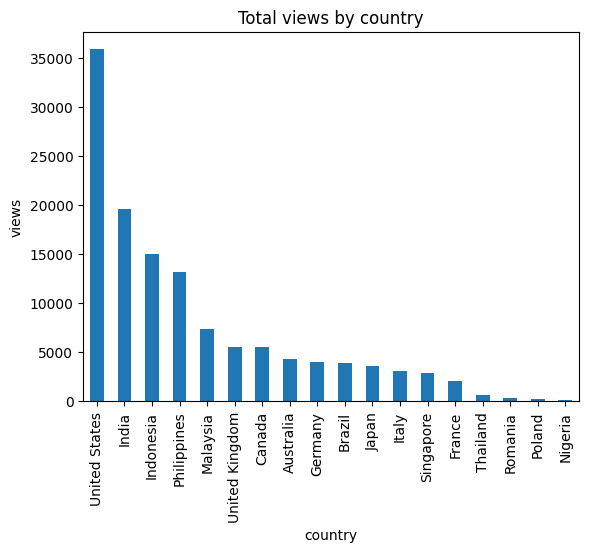

In [49]:
countryviews = september.groupby('country')['number'].sum().sort_values(ascending=False)
countryviews.head(20).plot.bar()
plt.title("Total views by country")
plt.xlabel("country")
plt.ylabel("views")
plt.show()

#### same thing but grouping by article not country

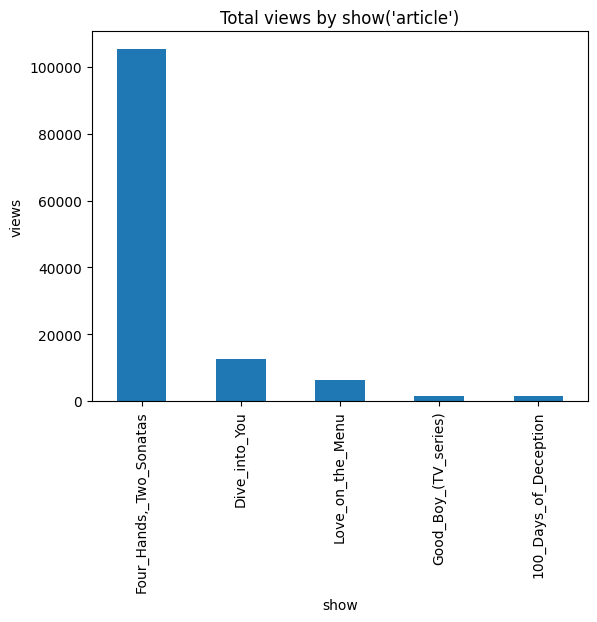

In [50]:
articleviews = september.groupby('article')['number'].sum().sort_values(ascending=False)
articleviews.head(20).plot.bar()
plt.title("Total views by show('article')")
plt.xlabel("show")
plt.ylabel("views")
plt.show()

##### The Wikipedia peaches do not really show a strong correlation with my drama list ratings. While Four Hands Two Sonatas ranks high in the rating and the views, as seen in the bar charts, the pattern breaks down for the remaining shows. Dive into you has the lowest rating yet a super high pageview count.  Good boy and 100 days of deception have much higher fan ratings than dive into you but both received a much smaller set of views across the entire month. It seems like ratings on my drama list don't seem to correlate with Wikipedia interest in traffic. Therefore, the community review scores for my drama lists don't seem to really be a good indicator of mainstream views for these shows.